# Week 2 — Day 1 — Exercises XP

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'analysis_helpers.py').exists():
    if root == root.parent:
        raise FileNotFoundError('Ouvrir depuis Week2/day1 ou un sous-dossier')
    root = root.parent
sys.path.insert(0, str(root))
from analysis_helpers import *
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)


Source : chapitre Octopus 4784. Les tâches numérotées demandent trois jeux de données à l'exercice 2, puis Iris à l'exercice 4. Les fichiers GitHub fournis remplacent Kaggle comme le précise l'énoncé. Les réponses écrites 1, 6 et 7 sont dans `reponses.md`.

## Exercice 1 — Introduction
Voir le rapport dans `reponses.md`, section 1.

## Exercice 2 — Charger et décrire les trois datasets

In [2]:
sleep = load('How Much Sleep Do Americans')
mental = load('Global Trends in Mental Health Disorder', low_memory=False)
credit = load('Credit Card Approvals (Clean Data)', 'clean_dataset.csv')
for name, df in [('Sommeil', sleep), ('Santé mentale', mental), ('Crédit', credit)]:
    print(name, df.shape)
    display(df.head())
    display(df.isna().sum().rename('valeurs manquantes').to_frame())
    df.info()

Sommeil (945, 9)


,index,Year,Period,Avg hrs per day sleeping,Standard Error,Type of Days,Age Group,Activity,Sex
0,0,2003,Annual,8.57,0.018,All days,15 years and over,Sleeping,Both
1,1,2004,Annual,8.55,0.026,All days,15 years and over,Sleeping,Both
2,2,2005,Annual,8.62,0.023,All days,15 years and over,Sleeping,Both
3,3,2006,Annual,8.63,0.024,All days,15 years and over,Sleeping,Both
4,4,2007,Annual,8.57,0.024,All days,15 years and over,Sleeping,Both


,valeurs manquantes
index,0
Year,0
Period,0
Avg hrs per day sleeping,0
Standard Error,0
Type of Days,0
Age Group,0
Activity,0
Sex,0


<class 'pandas.DataFrame'>
RangeIndex: 945 entries, 0 to 944
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   index                     945 non-null    int64  
 1   Year                      945 non-null    int64  
 2   Period                    945 non-null    str    
 3   Avg hrs per day sleeping  945 non-null    float64
 4   Standard Error            945 non-null    float64
 5   Type of Days              945 non-null    str    
 6   Age Group                 945 non-null    str    
 7   Activity                  945 non-null    str    
 8   Sex                       945 non-null    str    
dtypes: float64(2), int64(2), str(5)
memory usage: 66.6 KB
Santé mentale (108553, 11)


,index,Entity,Code,Year,Schizophrenia (%),Bipolar disorder (%),Eating disorders (%),Anxiety disorders (%),Drug use disorders (%),Depression (%),Alcohol use disorders (%)
0,0,Afghanistan,AFG,1990,0.16056,0.697779,0.101855,4.828830,1.677082,4.071831,0.672404
1,1,Afghanistan,AFG,1991,0.160312,0.697961,0.099313,4.829740,1.684746,4.079531,0.671768
2,2,Afghanistan,AFG,1992,0.160135,0.698107,0.096692,4.831108,1.694334,4.088358,0.670644
3,3,Afghanistan,AFG,1993,0.160037,0.698257,0.094336,4.830864,1.705320,4.096190,0.669738
4,4,Afghanistan,AFG,1994,0.160022,0.698469,0.092439,4.829423,1.716069,4.099582,0.669260


,valeurs manquantes
index,0
Entity,0
Code,5412
Year,0
Schizophrenia (%),82678
Bipolar disorder (%),89147
Eating disorders (%),8317
Anxiety disorders (%),102085
Drug use disorders (%),102085
Depression (%),102085


<class 'pandas.DataFrame'>
RangeIndex: 108553 entries, 0 to 108552
Data columns (total 11 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   index                      108553 non-null  int64  
 1   Entity                     108553 non-null  str    
 2   Code                       103141 non-null  str    
 3   Year                       108553 non-null  str    
 4   Schizophrenia (%)          25875 non-null   str    
 5   Bipolar disorder (%)       19406 non-null   str    
 6   Eating disorders (%)       100236 non-null  str    
 7   Anxiety disorders (%)      6468 non-null    float64
 8   Drug use disorders (%)     6468 non-null    float64
 9   Depression (%)             6468 non-null    float64
 10  Alcohol use disorders (%)  6468 non-null    float64
dtypes: float64(4), int64(1), str(6)
memory usage: 9.1 MB
Crédit (690, 16)


,Gender,Age,Debt,Married,BankCustomer,Industry,Ethnicity,YearsEmployed,PriorDefault,Employed,CreditScore,DriversLicense,Citizen,ZipCode,Income,Approved
0,1,30.83,0.000,1,1,Industrials,White,1.25,1,1,1,0,ByBirth,202,0,1
1,0,58.67,4.460,1,1,Materials,Black,3.04,1,1,6,0,ByBirth,43,560,1
2,0,24.50,0.500,1,1,Materials,Black,1.50,1,0,0,0,ByBirth,280,824,1
3,1,27.83,1.540,1,1,Industrials,White,3.75,1,1,5,1,ByBirth,100,3,1
4,1,20.17,5.625,1,1,Industrials,White,1.71,1,0,0,0,ByOtherMeans,120,0,1


,valeurs manquantes
Gender,0
Age,0
Debt,0
Married,0
BankCustomer,0
Industry,0
Ethnicity,0
YearsEmployed,0
PriorDefault,0
Employed,0


<class 'pandas.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          690 non-null    int64  
 1   Age             690 non-null    float64
 2   Debt            690 non-null    float64
 3   Married         690 non-null    int64  
 4   BankCustomer    690 non-null    int64  
 5   Industry        690 non-null    str    
 6   Ethnicity       690 non-null    str    
 7   YearsEmployed   690 non-null    float64
 8   PriorDefault    690 non-null    int64  
 9   Employed        690 non-null    int64  
 10  CreditScore     690 non-null    int64  
 11  DriversLicense  690 non-null    int64  
 12  Citizen         690 non-null    str    
 13  ZipCode         690 non-null    int64  
 14  Income          690 non-null    int64  
 15  Approved        690 non-null    int64  
dtypes: float64(3), int64(10), str(3)
memory usage: 86.4 KB


Sommeil : estimations annuelles des heures quotidiennes de sommeil, ventilées par sexe, âge et type de jour ; il ne s'agit pas de mesures individuelles. Santé mentale : fichier présentant des indicateurs par territoire et année, avec une qualité hétérogène à vérifier. Crédit : caractéristiques de demandes et indicateur de décision ; `clean_dataset.csv` est la version nettoyée, `crx.csv` est la source sans en-tête.

In [3]:
# Diagnostic : le fichier de santé mentale contient des blocs de schémas différents.
mental_numeric = mental.drop(columns=['Entity','Code']).apply(pd.to_numeric,errors='coerce')
print('Années non numériques :',mental_numeric['Year'].isna().sum())
rate_cols = [c for c in mental if '%' in c]
print('Valeurs hors [0,100] sous les en-têtes de taux :')
display(((mental_numeric[rate_cols]<0)|(mental_numeric[rate_cols]>100)).sum())


Années non numériques : 143
Valeurs hors [0,100] sous les en-têtes de taux :


Schizophrenia (%)             6468
Bipolar disorder (%)          6468
Eating disorders (%)         93766
Anxiety disorders (%)            0
Drug use disorders (%)           0
Depression (%)                   0
Alcohol use disorders (%)        0
dtype: int64

Le fichier santé mentale ne constitue pas une table de prévalence homogène : certaines années ne sont pas numériques et certains chiffres dépassent 100 sous des en-têtes en pourcentage. La classification ci-dessous décrit le sens annoncé des colonnes, pas la validité de toutes les cellules. Aucune moyenne de prévalence globale n'est calculée sur ce mélange de schémas ; il faudrait retrouver le dictionnaire et séparer les blocs sources avant une analyse épidémiologique.

## Exercice 3 — Type conceptuel de chaque colonne

In [4]:
sleep_types = {
'index':'Qualitative nominale : identifiant de ligne, sans valeur de mesure.',
'Year':'Quantitative discrète temporelle : année ; des différences ont un sens.',
'Period':'Qualitative nominale : périodicité de publication.',
'Avg hrs per day sleeping':'Quantitative continue : durée moyenne en heures.',
'Standard Error':'Quantitative continue : incertitude sur une estimation.',
'Type of Days':'Qualitative nominale : catégorie de jours.',
'Age Group':'Qualitative ordinale : tranche d’âge ordonnée, pas un âge individuel.',
'Activity':'Qualitative nominale : activité.', 'Sex':'Qualitative nominale : groupe de population.'}
mental_types = {c: ('Quantitative continue : taux de prévalence en pourcentage (conversion et contrôle nécessaires).' if '%' in c else 'Qualitative nominale : territoire ou code.') for c in mental}
mental_types.update({'index':'Qualitative nominale : identifiant de ligne.', 'Year':'Quantitative discrète temporelle : année à valider.'})
credit_types = {c:'Qualitative nominale : catégorie ou indicateur binaire, même si stocké comme nombre.' for c in credit}
credit_types.update({c:'Quantitative continue : mesure ou durée.' for c in ['Age','Debt','YearsEmployed']})
credit_types.update({'CreditScore':'Quantitative discrète : compte de références/indicateur numérique à vérifier dans le dictionnaire source.', 'Income':'Quantitative : montant de revenu déclaré.', 'ZipCode':'Qualitative nominale : code postal, ne pas en calculer la moyenne.'})
for name, df, mapping in [('sleep',sleep,sleep_types),('mental',mental,mental_types),('credit',credit,credit_types)]:
    table = classify(df,mapping)
    display(table)
    table.to_csv(RESULTS / f'xp_types_{name}.csv', index=False)

,colonne,dtype pandas,type et justification
0,index,int64,"Qualitative nominale : identifiant de ligne, s..."
1,Year,int64,Quantitative discrète temporelle : année ; des...
2,Period,str,Qualitative nominale : périodicité de publicat...
3,Avg hrs per day sleeping,float64,Quantitative continue : durée moyenne en heures.
4,Standard Error,float64,Quantitative continue : incertitude sur une es...
5,Type of Days,str,Qualitative nominale : catégorie de jours.
6,Age Group,str,"Qualitative ordinale : tranche d’âge ordonnée,..."
7,Activity,str,Qualitative nominale : activité.
8,Sex,str,Qualitative nominale : groupe de population.


,colonne,dtype pandas,type et justification
0,index,int64,Qualitative nominale : identifiant de ligne.
1,Entity,str,Qualitative nominale : territoire ou code.
2,Code,str,Qualitative nominale : territoire ou code.
3,Year,str,Quantitative discrète temporelle : année à val...
4,Schizophrenia (%),str,Quantitative continue : taux de prévalence en ...
5,Bipolar disorder (%),str,Quantitative continue : taux de prévalence en ...
6,Eating disorders (%),str,Quantitative continue : taux de prévalence en ...
7,Anxiety disorders (%),float64,Quantitative continue : taux de prévalence en ...
8,Drug use disorders (%),float64,Quantitative continue : taux de prévalence en ...
9,Depression (%),float64,Quantitative continue : taux de prévalence en ...


,colonne,dtype pandas,type et justification
0,Gender,int64,Qualitative nominale : catégorie ou indicateur...
1,Age,float64,Quantitative continue : mesure ou durée.
2,Debt,float64,Quantitative continue : mesure ou durée.
3,Married,int64,Qualitative nominale : catégorie ou indicateur...
4,BankCustomer,int64,Qualitative nominale : catégorie ou indicateur...
5,Industry,str,Qualitative nominale : catégorie ou indicateur...
6,Ethnicity,str,Qualitative nominale : catégorie ou indicateur...
7,YearsEmployed,float64,Quantitative continue : mesure ou durée.
8,PriorDefault,int64,Qualitative nominale : catégorie ou indicateur...
9,Employed,int64,Qualitative nominale : catégorie ou indicateur...


## Exercice 4 — Iris : classification de toutes les colonnes

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


,colonne,dtype pandas,type et justification
0,Id,int64,Qualitative nominale : identifiant ; pas une m...
1,SepalLengthCm,float64,Quantitative continue : longueur mesurée en ce...
2,SepalWidthCm,float64,Quantitative continue : longueur mesurée en ce...
3,PetalLengthCm,float64,Quantitative continue : longueur mesurée en ce...
4,PetalWidthCm,float64,Quantitative continue : longueur mesurée en ce...
5,Species,str,Qualitative nominale : espèce de fleur.


Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
dtype: int64

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
mean,5.843333,3.054000,3.758667,1.198667
median,5.800000,3.000000,4.350000,1.300000
std,0.828066,0.433594,1.764420,0.763161


Modes :


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.0,3.0,1.5,0.2


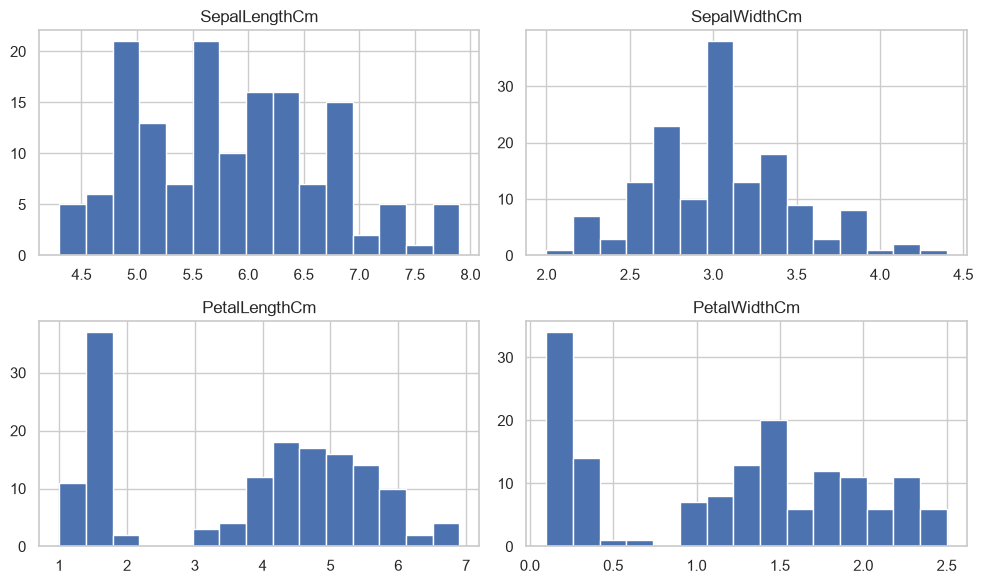

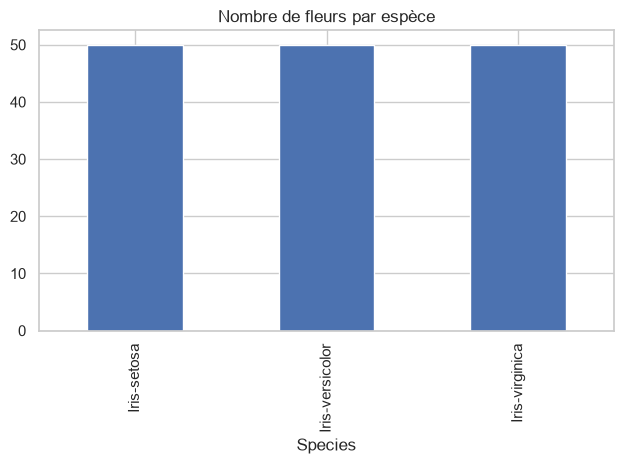

In [5]:
iris = load('Iris Dataset')
iris_types = {c:'Quantitative continue : longueur mesurée en centimètres.' for c in iris.columns if c.endswith('Cm')}
iris_types.update({'Id':'Qualitative nominale : identifiant ; pas une mesure botanique.', 'Species':'Qualitative nominale : espèce de fleur.'})
display(iris.head())
display(classify(iris, iris_types))
display(iris.groupby('Species').size())
measurements = iris.filter(regex='Cm$')
display(measurements.agg(['mean','median','std']))
print('Modes :'); display(measurements.mode())
measurements.hist(figsize=(10,6), bins=15); plt.tight_layout(); plt.show()
iris['Species'].value_counts().plot.bar(title='Nombre de fleurs par espèce'); plt.tight_layout(); plt.show()

Les mesures sont continues bien qu'arrondies au dixième. La moyenne et la médiane décrivent une variable numérique ; le mode peut contenir plusieurs valeurs. Les histogrammes résument les mesures toutes espèces confondues, ce qui peut masquer les différences entre espèces (étudiées dans Ninja 3).

## Exercice 5 — Choisir les colonnes intéressantes pour le sommeil

Catégories disponibles :
Period <StringArray>
['Annual']
Length: 1, dtype: str
Type of Days <StringArray>
['All days', 'Nonholiday weekdays', 'Weekend days and holidays']
Length: 3, dtype: str
Age Group <StringArray>
['15 years and over',    '15 to 24 years',    '25 to 34 years',
    '35 to 44 years',    '45 to 54 years',    '55 to 64 years',
 '65 years and over']
Length: 7, dtype: str
Activity <StringArray>
['Sleeping']
Length: 1, dtype: str
Sex <StringArray>
['Both', 'Men', 'Women']
Length: 3, dtype: str


,Year,Avg hrs per day sleeping,Standard Error
0,2003,8.57,0.018
1,2004,8.55,0.026
2,2005,8.62,0.023
3,2006,8.63,0.024
4,2007,8.57,0.024
5,2008,8.60,0.023
6,2009,8.67,0.023
7,2010,8.67,0.024
8,2011,8.71,0.026
9,2012,8.73,0.026


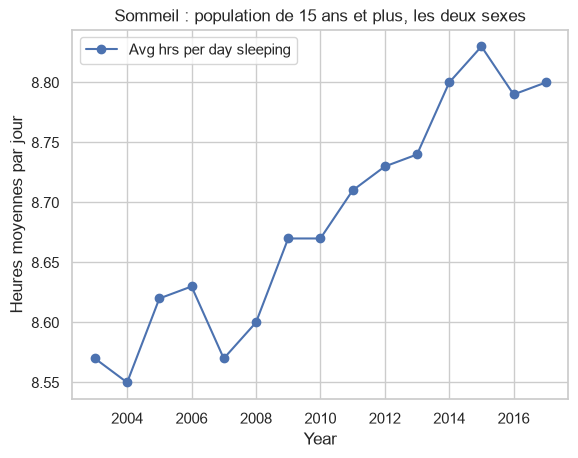

Écart dernière année - première année : 0.23 heure(s)


In [6]:
# Une même population contient des sous-groupes qui se recouvrent : ne pas les additionner.
print('Catégories disponibles :')
for col in ['Period','Type of Days','Age Group','Activity','Sex']:
    print(col, sleep[col].unique())
base = sleep[(sleep['Sex']=='Both') & (sleep['Age Group']=='15 years and over') & (sleep['Type of Days']=='All days')].copy()
assert not base.empty
base = base.sort_values('Year')
display(base[['Year','Avg hrs per day sleeping','Standard Error']])
base.plot(x='Year',y='Avg hrs per day sleeping',marker='o',title='Sommeil : population de 15 ans et plus, les deux sexes')
plt.ylabel('Heures moyennes par jour'); plt.show()
print('Écart dernière année - première année :', round(base.iloc[-1]['Avg hrs per day sleeping']-base.iloc[0]['Avg hrs per day sleeping'],3), 'heure(s)')

`Year` et `Avg hrs per day sleeping` permettent une tendance temporelle. `Sex`, `Age Group` et `Type of Days` permettent des comparaisons à année et population comparables. `Standard Error` renseigne l'incertitude : une différence brute ne prouve pas une différence statistiquement significative. Le graphique porte sur les estimations disponibles ; il n'identifie pas une cause.

## Exercices 6 et 7 — Structure et transformation
Voir `reponses.md` pour les cinq classifications et les quatre méthodes détaillées.

## Exercice 8 — Import Titanic train.csv

In [7]:
titanic = load('train')
display(titanic.head())
assert len(titanic) == 891

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Exercice 9 — Export Excel et JSON et vérification de relecture

In [8]:
simple = pd.DataFrame({'produit':['Cahier','Stylo','Classeur'], 'quantité':[3,10,2], 'prix_unitaire':[4.5,1.2,6.0]})
simple.to_excel(RESULTS / 'xp_ex9.xlsx',index=False)
simple.to_json(RESULTS / 'xp_ex9.json',orient='records',force_ascii=False,indent=2)
pd.testing.assert_frame_equal(simple, pd.read_excel(RESULTS / 'xp_ex9.xlsx'), check_dtype=False)
pd.testing.assert_frame_equal(simple, pd.read_json(RESULTS / 'xp_ex9.json'), check_dtype=False)
display(simple)
print('Exports relus et identiques.')

,produit,quantité,prix_unitaire
0,Cahier,3,4.5
1,Stylo,10,1.2
2,Classeur,2,6.0


Exports relus et identiques.


## Exercice 10 — JSON depuis l’URL fournie

In [9]:
# L’URL fournie est une archive Git LFS : téléchargement HTTPS puis lecture du JSON interne.
import requests, zipfile, io
from urllib.parse import quote
path = __import__('json').loads((ROOT / 'datasets.json').read_text())['posts']
url = 'https://media.githubusercontent.com/media/devtlv/Datasets-DA-Bootcamp-2-/main/' + quote(path)
response = requests.get(url, timeout=60)
response.raise_for_status()
with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    with archive.open('posts.json') as stream:
        posts = pd.read_json(stream)
display(posts.head(5))
assert len(posts) == 100 and {'userId','id','title','body'} <= set(posts)

,userId,id,title,body
0,1,1,sunt aut facere repellat provident occaecati e...,quia et suscipit\nsuscipit recusandae consequu...
1,1,2,qui est esse,est rerum tempore vitae\nsequi sint nihil repr...
2,1,3,ea molestias quasi exercitationem repellat qui...,et iusto sed quo iure\nvoluptatem occaecati om...
3,1,4,eum et est occaecati,ullam et saepe reiciendis voluptatem adipisci\...
4,1,5,nesciunt quas odio,repudiandae veniam quaerat sunt sed\nalias aut...
